In [ ]:
!pip install -q opencv-contrib-python==4.10.0.84 pandas scikit-learn matplotlib seaborn scikit-image joblib tensorflow

import os
import warnings
warnings.filterwarnings("ignore")
import io
import cv2
import joblib
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from base64 import b64decode, b64encode
from PIL import Image
from IPython.display import display, Javascript
from google.colab.output import eval_js

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.svm import SVC
from skimage.feature import hog

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import AveragePooling2D, Dropout, Flatten, Dense, Input
from tensorflow.keras.models import Model

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 9.5 MB/s eta 0:00:00
Mounted at /content/drive


In [ ]:
save_dir = "/content/drive/MyDrive/Colab Notebooks/Dataset/models3/"
images_folder = "/content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces"
csv_file = "/content/drive/MyDrive/Colab Notebooks/Dataset/data.csv"

IMG_SIZE = (100, 100)
CONFIDENCE_THRESHOLD = 0.65

# Load metadata
df = pd.read_csv(csv_file)
df["ID"] = df["ID"].astype(str)
print("Metadata head:")
print(df.head())
print("\nFound person folders for:", os.listdir(images_folder))

Metadata head:
      Role    ID          Name  Gender Faculty                  Course
0    Staff  E001  Henry Cavill    Male    FAFB                     NaN
1  Student  S001   Lisa Kudrow  Female    FAFB   Diploma in Accounting
2  Student  S002    Alia Bhatt  Female    FOAS  Bachelor in Bioscience
3    Staff  E002    Tom Cruise    Male    FOCS                     NaN
4    Staff  E003     Zac Efron    Male    FAFB                     NaN

Found person folders for: ['E001', 'S001', 'S002', 'E002', 'E003', 'S003', 'S004', 'E004', 'E005', 'S005', 'S006', 'S007', 'S008', 'S009', 'S010', 'S011', 'S012', 'E006', 'S013', 'S014', 'E007', 'S015', 'S016', 'E008', 'E009', 'S017', 'S018', 'S019', 'E010', 'S020', 'S022', 'S023', 'S024', 'S025', 'S021']


In [ ]:
# --- YuNet Face Detection ---
YUNET_MODEL_URL = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
YUNET_MODEL_PATH = "face_detection_yunet_2023mar.onnx"

YUNET_SCORE_THRESHOLD = 0.7   # min confidence to keep a detection
YUNET_NMS_THRESHOLD = 0.3     # non-max suppression IoU threshold
YUNET_TOP_K = 5000            # max detections kept before NMS
YUNET_MIN_FACE_SIZE = 60      # matches the old Haar minSize=(60, 60)

urllib.request.urlretrieve(YUNET_MODEL_URL,YUNET_MODEL_PATH)

face_detector = cv2.FaceDetectorYN.create(
    YUNET_MODEL_PATH, "", (320, 320),
    YUNET_SCORE_THRESHOLD, YUNET_NMS_THRESHOLD, YUNET_TOP_K,
)

def detect_faces_yunet(image):
    """Runs YuNet on a BGR image and returns a list of (x, y, w, h) int boxes,
    the same shape CascadeClassifier.detectMultiScale used to return -- so
    downstream code (largest-face selection, cropping) is unchanged."""
    h, w = image.shape[:2]
    face_detector.setInputSize((w, h))
    _, faces = face_detector.detect(image)
    boxes = []
    if faces is not None:
        for f in faces:
            x, y, fw, fh = f[:4]
            x, y, fw, fh = int(round(x)), int(round(y)), int(round(fw)), int(round(fh))
            if fw >= YUNET_MIN_FACE_SIZE and fh >= YUNET_MIN_FACE_SIZE:
                boxes.append((max(x, 0), max(y, 0), fw, fh))
    return boxes

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def preprocess_face(face_gray_crop):
    """Resize, CLAHE contrast-normalize, and pixel-normalize a cropped grayscale
    face. Used identically for both training feature extraction and live
    inference so the two pipelines can't drift out of sync with each other."""
    face = cv2.resize(face_gray_crop, IMG_SIZE)
    face = clahe.apply(face)
    face = face.astype(np.float32) / 255.0  # pixel normalization to [0, 1]
    return face

def detect_and_crop_face(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    faces = detect_faces_yunet(image)
    if len(faces) == 0: return None
    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
    return preprocess_face(gray[y:y+h, x:x+w])

# --- HOG & Augmentation ---
def extract_hog_features(img_gray):
    return hog(
        img_gray, orientations=12, pixels_per_cell=(6, 6),
        cells_per_block=(3, 3), block_norm='L2-Hys',
        transform_sqrt=True, visualize=False
    )

def augment_face(face_norm, n_copies=4):
    # face_norm is already resized + CLAHE'd + pixel-normalized to float32 [0,1].
    # n_copies lets you augment minority classes more than majority classes.
    augmented = [face_norm]
    if n_copies >= 2:
        augmented.append(cv2.flip(face_norm, 1))  # horizontal flip
    if n_copies >= 3:
        M_pos = cv2.getRotationMatrix2D((IMG_SIZE[0]//2, IMG_SIZE[1]//2), 8, 1.0)
        augmented.append(cv2.warpAffine(face_norm, M_pos, IMG_SIZE, borderMode=cv2.BORDER_REPLICATE))  # +8 deg
    if n_copies >= 4:
        M_neg = cv2.getRotationMatrix2D((IMG_SIZE[0]//2, IMG_SIZE[1]//2), -8, 1.0)
        augmented.append(cv2.warpAffine(face_norm, M_neg, IMG_SIZE, borderMode=cv2.BORDER_REPLICATE))  # -8 deg
    if n_copies >= 5:
        augmented.append(np.clip(face_norm + 0.12, 0.0, 1.0).astype(np.float32))  # brighter
    if n_copies >= 6:
        augmented.append(np.clip(face_norm - 0.12, 0.0, 1.0).astype(np.float32))  # darker
    return augmented

# --- Pretrained Face Mask Detector ---
MASK_MODEL_PATH = "mask_detector.h5"
MASK_MODEL_URL = "https://raw.githubusercontent.com/chandrikadeb7/Face-Mask-Detection/master/mask_detector.model"
MASK_IMG_SIZE = 224

if not os.path.exists(MASK_MODEL_PATH):
    urllib.request.urlretrieve(MASK_MODEL_URL, MASK_MODEL_PATH)

_base = MobileNetV2(weights=None, include_top=False, input_tensor=Input(shape=(MASK_IMG_SIZE, MASK_IMG_SIZE, 3)))
_head = AveragePooling2D(pool_size=(7, 7))(_base.output)
_head = Flatten(name="flatten")(_head)
_head = Dense(128, activation="relu")(_head)
_head = Dropout(0.5)(_head)
_head = Dense(2, activation="softmax")(_head)
mask_net = Model(inputs=_base.input, outputs=_head)
mask_net.load_weights(MASK_MODEL_PATH)

def is_wearing_mask(face_bgr):
    face_rgb = cv2.cvtColor(face_bgr, cv2.COLOR_BGR2RGB)
    face_resized = cv2.resize(face_rgb, (MASK_IMG_SIZE, MASK_IMG_SIZE))
    face_array = tf.keras.preprocessing.image.img_to_array(face_resized)
    face_array = tf.keras.applications.mobilenet_v2.preprocess_input(face_array)
    face_array = np.expand_dims(face_array, axis=0)
    (mask_prob, without_mask_prob) = mask_net.predict(face_array, verbose=0)[0]
    return mask_prob > without_mask_prob

In [ ]:
X_TRAIN_CACHE = os.path.join(save_dir, "X_train_features.npy")
Y_TRAIN_CACHE = os.path.join(save_dir, "y_train.npy")
X_TEST_CACHE  = os.path.join(save_dir, "X_test_features.npy")
Y_TEST_CACHE  = os.path.join(save_dir, "y_test.npy")

RANDOM_SEED = 42  # fixed seed for the split

if all(os.path.exists(p) for p in [X_TRAIN_CACHE, Y_TRAIN_CACHE, X_TEST_CACHE, Y_TEST_CACHE]):
    print("Loading cached features (delete these files to force re-extraction)...")
    X_train_raw = np.load(X_TRAIN_CACHE)
    y_train_raw = np.load(Y_TRAIN_CACHE)
    X_test_raw  = np.load(X_TEST_CACHE)
    y_test_raw  = np.load(Y_TEST_CACHE)
else:
    valid_exts = (".jpg", ".jpeg", ".png", ".webp")
    person_ids = sorted([p for p in os.listdir(images_folder)
                          if os.path.isdir(os.path.join(images_folder, p))])

    # --- Split by ORIGINAL photo first, before any augmentation ---
    train_files_by_person = {}
    test_files_by_person = {}

    for pid in person_ids:
        person_dir = os.path.join(images_folder, pid)
        files = [f for f in os.listdir(person_dir) if f.lower().endswith(valid_exts)]
        if len(files) < 4:
            # too few photos to hold any out for testing
            train_files_by_person[pid] = files
            test_files_by_person[pid] = []
            print(f"[split] {pid}: only {len(files)} original photo(s) -- all used for training, none held out for test")
        else:
            train_f, test_f = train_test_split(files, test_size=0.2, random_state=RANDOM_SEED)
            train_files_by_person[pid] = train_f
            test_files_by_person[pid] = test_f

    max_train_count = max(len(v) for v in train_files_by_person.values())
    n_copies_per_person = {
        pid: int(np.clip(round(max_train_count / max(len(train_files_by_person[pid]), 1)), 1, 6))
        for pid in person_ids
    }

    X_train_raw, y_train_raw = [], []
    X_test_raw, y_test_raw = [], []
    skipped = 0

    print("Extracting HOG features (train: augmented, test: original photos only)...")
    for pid in person_ids:
        person_dir = os.path.join(images_folder, pid)
        n_copies = n_copies_per_person[pid]

        # Training images: detect, crop, augment, extract
        for filename in train_files_by_person[pid]:
            image = cv2.imread(os.path.join(person_dir, filename))
            if image is None:
                skipped += 1
                continue
            face = detect_and_crop_face(image)
            if face is None:
                skipped += 1
                continue
            for aug_face in augment_face(face, n_copies=n_copies):
                X_train_raw.append(extract_hog_features(aug_face))
                y_train_raw.append(pid)

        # Test images: detect, crop, extract -- no augmentation
        for filename in test_files_by_person[pid]:
            image = cv2.imread(os.path.join(person_dir, filename))
            if image is None:
                skipped += 1
                continue
            face = detect_and_crop_face(image)
            if face is None:
                skipped += 1
                continue
            X_test_raw.append(extract_hog_features(face))
            y_test_raw.append(pid)

    X_train_raw = np.array(X_train_raw)
    y_train_raw = np.array(y_train_raw)
    X_test_raw = np.array(X_test_raw)
    y_test_raw = np.array(y_test_raw)

    os.makedirs(save_dir, exist_ok=True)
    np.save(X_TRAIN_CACHE, X_train_raw)
    np.save(Y_TRAIN_CACHE, y_train_raw)
    np.save(X_TEST_CACHE, X_test_raw)
    np.save(Y_TEST_CACHE, y_test_raw)
    print("Cached features saved -- re-running this cell will now load instantly.")

print(f"Train feature vectors (incl. augmentation): {len(X_train_raw)}")
print(f"Test feature vectors (original photos only): {len(X_test_raw)}")
print(f"Number of classes: {len(np.unique(np.concatenate([y_train_raw, y_test_raw])))}")

print("\nTrain count per person:")
print(pd.Series(y_train_raw).value_counts())
print("\nTest count per person:")
print(pd.Series(y_test_raw).value_counts())

Loading cached features (delete these files to force re-extraction)...
Train feature vectors (incl. augmentation): 3111
Test feature vectors (original photos only): 537
Number of classes: 35

Train count per person:
S024    126
S023    126
E007    122
S017    116
E006    114
S002    112
S016    110
S008    110
E010    106
S014    102
S001    102
S018     98
S013     94
S004     93
E009     91
S020     90
E004     90
S003     84
E005     83
E002     82
S011     81
S007     80
E001     77
S010     77
S005     72
S015     71
S006     71
S012     70
S009     70
S019     69
E003     67
S022     64
S021     64
S025     64
E008     63
Name: count, dtype: int64

Test count per person:
E009    22
S003    21
S010    21
S011    20
E005    20
S005    20
S006    19
S019    18
S015    18
S009    18
S012    17
S023    16
E003    16
E001    16
S022    16
S025    16
S021    16
S024    16
S002    15
S017    15
E008    15
E010    14
S016    14
S008    14
E007    14
E006    14
S018    13
E004    13
S001  

In [ ]:
# Training
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Fit the label encoder on the union of train+test labels so both sets encode consistently
label_encoder = LabelEncoder()
label_encoder.fit(np.concatenate([y_train_raw, y_test_raw]))
y_train = label_encoder.transform(y_train_raw)
y_test = label_encoder.transform(y_test_raw)

X_train, X_test = X_train_raw, X_test_raw

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=300, random_state=RANDOM_SEED)),
    ("svc", SVC(class_weight="balanced")),
])

param_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.01, 0.001],
    "svc__kernel": ["rbf"],
}

print("Training SVM with Grid Search (this may take a moment)...")
grid_search = GridSearchCV(
    pipeline,
    param_grid, cv=3, n_jobs=-1, verbose=1
)
grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_

best_model = clone(pipeline)
best_model.set_params(svc__probability=True, **best_params)
best_model.fit(X_train, y_train)

fitted_pca = best_model.named_steps["pca"]
print(f"\nBest SVM Parameters: {best_params}")
print(f"PCA retained {fitted_pca.explained_variance_ratio_.sum()*100:.1f}% of variance "
      f"using {fitted_pca.n_components_} components (fit on the training set only).")


Training SVM with Grid Search (this may take a moment)...
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best SVM Parameters: {'svc__C': 10, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
PCA retained 58.2% of variance using 300 components (fit on the training set only).


Training Accuracy: 100.00%
Test Accuracy:     74.49%

Classification Report:
              precision    recall  f1-score   support

        E001       0.75      0.75      0.75        16
        E002       0.50      0.82      0.62        11
        E003       0.76      0.81      0.79        16
        E004       0.48      0.77      0.59        13
        E005       0.65      0.55      0.59        20
        E006       0.80      0.86      0.83        14
        E007       0.60      0.86      0.71        14
        E008       0.90      0.60      0.72        15
        E009       0.90      0.86      0.88        22
        E010       1.00      0.93      0.96        14
        S001       0.53      0.77      0.62        13
        S002       0.60      0.40      0.48        15
        S003       0.83      0.90      0.86        21
        S004       0.80      0.50      0.62         8
        S005       0.88      0.70      0.78        20
        S006       0.82      0.47      0.60        19
    

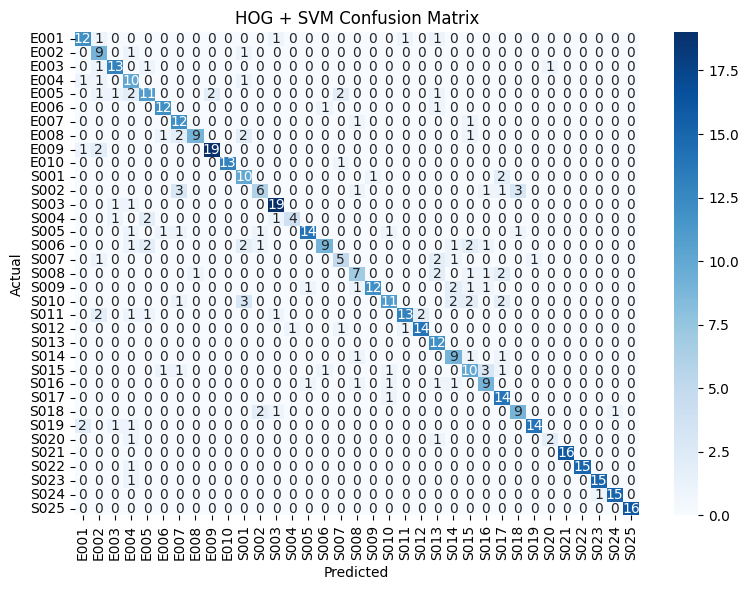

In [ ]:
# Evaluation of model
train_acc = best_model.score(X_train, y_train) * 100
test_acc = best_model.score(X_test, y_test) * 100

print(f"Training Accuracy: {train_acc:.2f}%")
print(f"Test Accuracy:     {test_acc:.2f}%\n")

y_pred = best_model.predict(X_test)
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_, zero_division=0))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('HOG + SVM Confusion Matrix')
plt.tight_layout()
plt.show()

Selected CONFIDENCE_THRESHOLD = 0.385 (maximizes F1 on out-of-fold training predictions)
  At this threshold -> precision: 0.855, recall: 0.864, F1: 0.860
  ROC AUC (confidence vs. correctness): 0.877


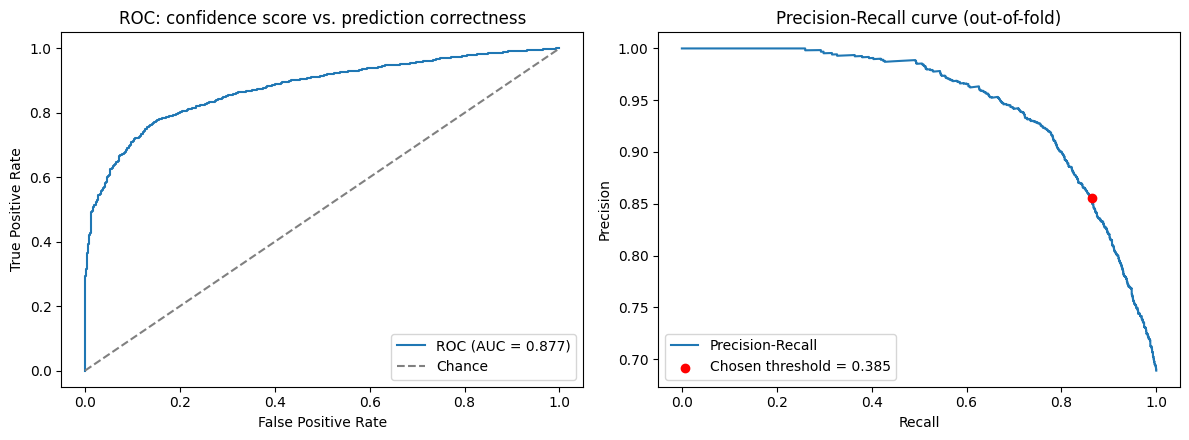

In [ ]:
# Confidence Threshold Selection
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, auc, precision_recall_curve, f1_score

proba_pipeline = clone(pipeline)
proba_pipeline.set_params(svc__probability=True, **best_params)
oof_probs = cross_val_predict(
    proba_pipeline, X_train, y_train, cv=5, method='predict_proba', n_jobs=-1
)

oof_pred = np.argmax(oof_probs, axis=1)
oof_conf = np.max(oof_probs, axis=1)
oof_correct = (oof_pred == y_train).astype(int)

# --- ROC curve: can confidence separate correct from incorrect predictions? ---
fpr, tpr, roc_thresholds = roc_curve(oof_correct, oof_conf)
roc_auc = auc(fpr, tpr)

# --- Precision-Recall curve, scanned for the F1-optimal threshold ---
precision, recall, pr_thresholds = precision_recall_curve(oof_correct, oof_conf)
f1_scores = np.divide(
    2 * precision * recall, precision + recall,
    out=np.zeros_like(precision), where=(precision + recall) > 0
)
# precision/recall have one more element than pr_thresholds; align them
best_idx = np.argmax(f1_scores[:-1]) if len(f1_scores) > 1 else 0
CONFIDENCE_THRESHOLD = float(pr_thresholds[best_idx]) if len(pr_thresholds) > 0 else 0.5

print(f"Selected CONFIDENCE_THRESHOLD = {CONFIDENCE_THRESHOLD:.3f} "
      f"(maximizes F1 on out-of-fold training predictions)")
print(f"  At this threshold -> precision: {precision[best_idx]:.3f}, "
      f"recall: {recall[best_idx]:.3f}, F1: {f1_scores[best_idx]:.3f}")
print(f"  ROC AUC (confidence vs. correctness): {roc_auc:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(fpr, tpr, label=f"ROC (AUC = {roc_auc:.3f})")
ax[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax[0].set_xlabel("False Positive Rate")
ax[0].set_ylabel("True Positive Rate")
ax[0].set_title("ROC: confidence score vs. prediction correctness")
ax[0].legend(loc="lower right")

ax[1].plot(recall, precision, label="Precision-Recall")
ax[1].scatter(recall[best_idx], precision[best_idx], color="red", zorder=5,
              label=f"Chosen threshold = {CONFIDENCE_THRESHOLD:.3f}")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall curve (out-of-fold)")
ax[1].legend(loc="lower left")

plt.tight_layout()
plt.show()


In [ ]:
# Evaluates the chosen threshold on the test set
test_probs = best_model.predict_proba(X_test)
test_pred = np.argmax(test_probs, axis=1)
test_conf = np.max(test_probs, axis=1)
test_correct = (test_pred == y_test)

accepted = test_conf >= CONFIDENCE_THRESHOLD
n_accepted = accepted.sum()

print(f"Test predictions accepted (confidence >= {CONFIDENCE_THRESHOLD:.3f}): "
      f"{n_accepted}/{len(y_test)} ({100*n_accepted/len(y_test):.1f}%)")
if n_accepted > 0:
    print(f"Accuracy among accepted predictions:  {100*test_correct[accepted].mean():.2f}%")
n_rejected_but_correct = np.sum((~accepted) & test_correct)
print(f"Correct predictions rejected by the threshold: {n_rejected_but_correct} "
      f"(would have been right, but confidence was below the cutoff)")


Test predictions accepted (confidence >= 0.385): 401/537 (74.7%)
Accuracy among accepted predictions:  86.53%
Correct predictions rejected by the threshold: 55 (would have been right, but confidence was below the cutoff)


In [ ]:
# Save models
joblib.dump(best_model, os.path.join(save_dir, "face_svm_hog_pipeline.pkl"))
np.save(os.path.join(save_dir, "classes_hog.npy"), label_encoder.classes_)

np.save(os.path.join(save_dir, "confidence_threshold_hog.npy"), CONFIDENCE_THRESHOLD)
print("Saved all files.")

Saved SVM pipeline (scaler + PCA + SVC bundled together) and label classes.
